In [2]:
# # Exploratory Data Analysis and Deep Learning-Based Student Performance Analysis

In [3]:
# Dataset: UCI Student Performance (Mathematics)

In [4]:
# Run in Google Colab. This notebook downloads the dataset, performs EDA,

In [1]:
# creates visualizations, trains an MLP classifier, and evaluates it.

!pip -q install ucimlrepo tensorflow scikit-learn seaborn

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

sns.set_theme()
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


In [5]:
# 1. Acquire data from the UCI Machine Learning Repository
dataset = fetch_ucirepo(id=320)
X_all = dataset.data.features.copy()
y_all = dataset.data.targets.copy()
df = pd.concat([X_all, y_all], axis=1)


In [6]:
# Select the mathematics dataset and standardize column names.

In [7]:
# UCI returns the full combined dataset for this repository ID in some versions.

In [8]:
# If a subject column exists, retain Mathematics; otherwise use the provided records.
if "subject" in df.columns:
    df = df[df["subject"].astype(str).str.lower().str.contains("math")].copy()

print("Dataset shape:", df.shape)
print("Number of features/fields:", df.shape[1])
display(df.head())
display(df.info())
display(df.describe(include="all").T)
print("Missing values by column:\n", df.isna().sum().sort_values(ascending=False).head(15))
print("Duplicate rows:", df.duplicated().sum())


Dataset shape: (649, 33)
Number of features/fields: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values by column:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
dtype: int64
Duplicate rows: 0


In [9]:
# If the UCI API returns features and target separately with G3 target name,

In [10]:
# normalize target naming and ensure G3 exists.
if "G3" not in df.columns:
    target_candidates = [c for c in df.columns if str(c).lower() in ("g3", "final grade", "final_grade")]
    if target_candidates:
        df = df.rename(columns={target_candidates[0]: "G3"})
if "G3" not in df.columns:
    raise ValueError("Final grade column G3 was not found. Check the UCI dataset schema.")


In [11]:
# 2. Cleaning and transformation
df = df.drop_duplicates().copy()

In [12]:
# This dataset is documented by UCI as having no missing values. The imputer is retained

In [13]:
# in the model pipeline to make the workflow robust to missing values.
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")
df = df.dropna(subset=["G3"]).copy()


In [14]:
# Derived binary target: pass if final grade >= 10 on the original 0–20 scale.

In [15]:
# G1 and G2 are excluded to avoid using earlier grades that are highly correlated with G3

In [16]:
# and to make the prediction more useful from background/behavioral information.
df["pass"] = (df["G3"] >= 10).astype(int)
drop_cols = ["G3", "pass", "G1", "G2"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df["pass"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


In [17]:
# Split into train, validation and test sets: 70%, 15%, 15%.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765,
    random_state=RANDOM_STATE, stratify=y_train_full
)
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

print(f"Train: {X_train.shape[0]} | Validation: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print("Encoded input features:", X_train_p.shape[1])
print("Pass distribution:\n", y.value_counts(normalize=True).rename("proportion"))


Train: 453 | Validation: 98 | Test: 98
Encoded input features: 56
Pass distribution:
 pass
1    0.845917
0    0.154083
Name: proportion, dtype: float64


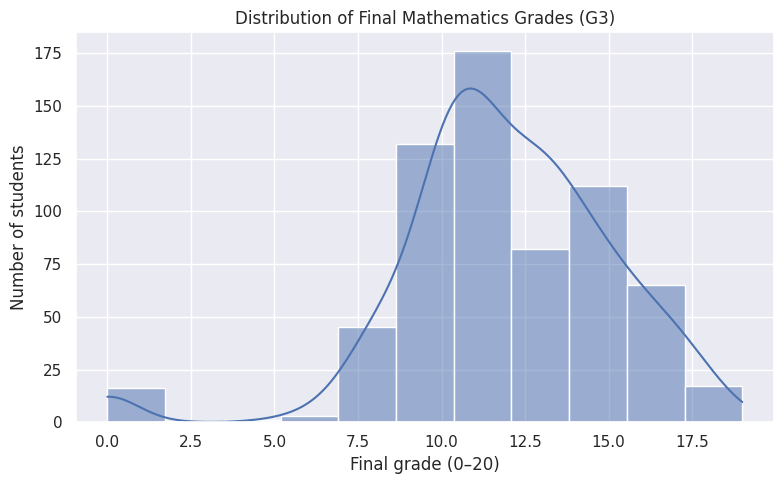

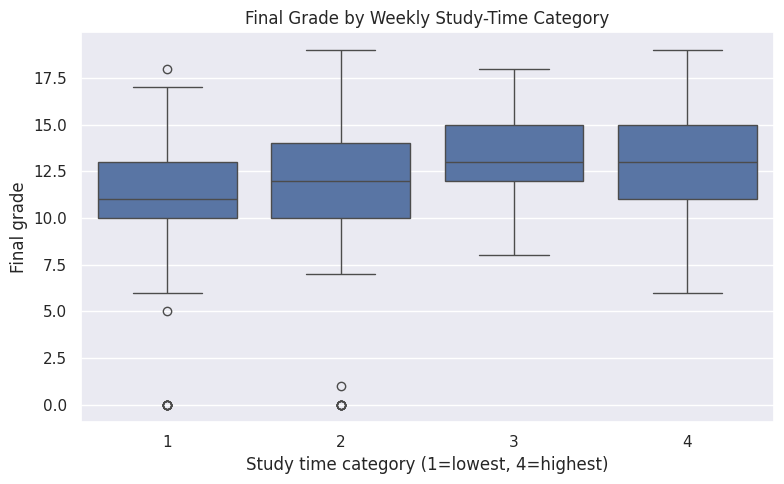

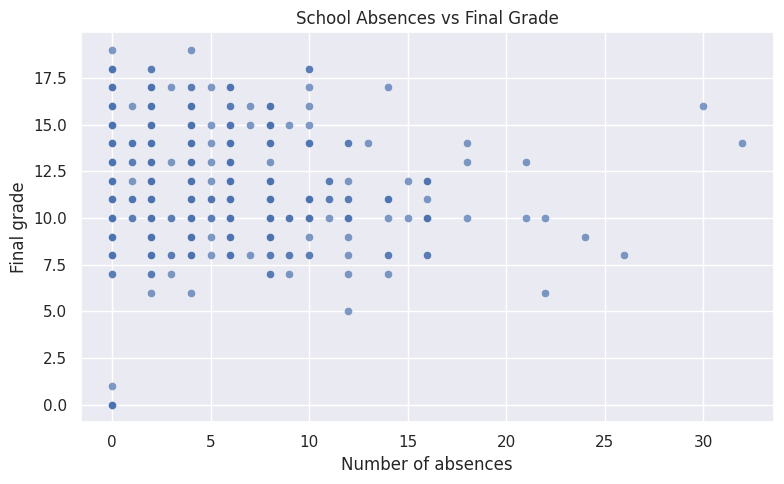

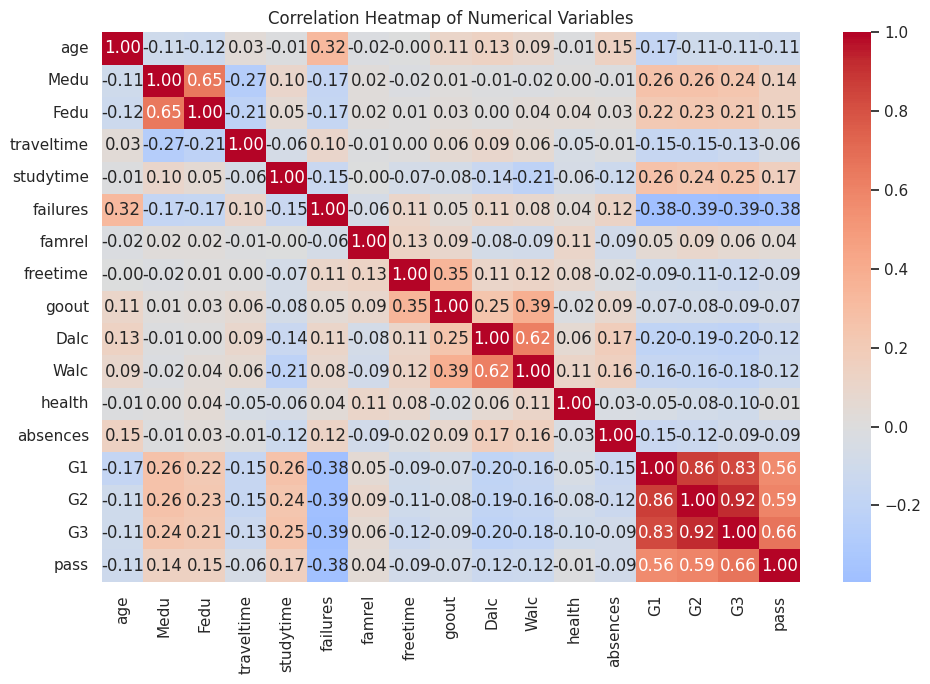

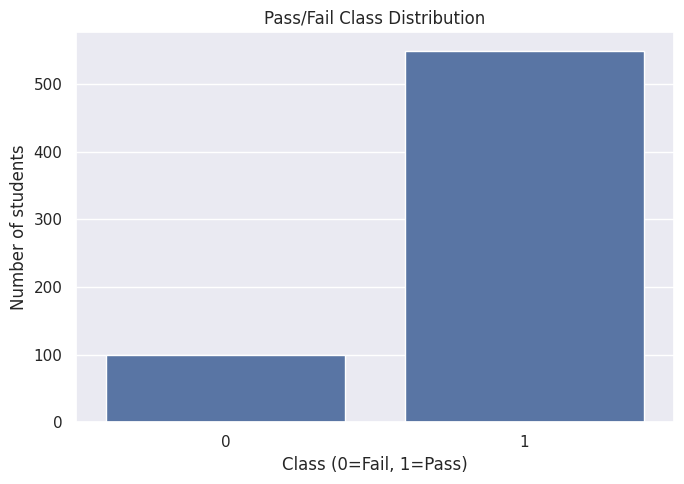

In [18]:
# 3. EDA visuals (all are generated from the selected dataset)
plt.figure(figsize=(8,5))
sns.histplot(df["G3"], bins=11, kde=True)
plt.title("Distribution of Final Mathematics Grades (G3)")
plt.xlabel("Final grade (0–20)"); plt.ylabel("Number of students")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Final Grade by Weekly Study-Time Category")
plt.xlabel("Study time category (1=lowest, 4=highest)"); plt.ylabel("Final grade")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="absences", y="G3", alpha=.7)
plt.title("School Absences vs Final Grade")
plt.xlabel("Number of absences"); plt.ylabel("Final grade")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10,7))
numeric_corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(numeric_corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="pass")
plt.title("Pass/Fail Class Distribution")
plt.xlabel("Class (0=Fail, 1=Pass)"); plt.ylabel("Number of students")
plt.tight_layout(); plt.show()


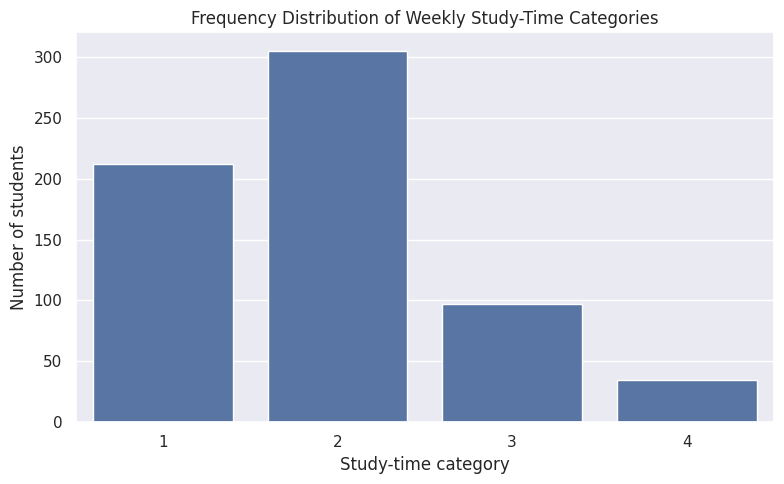

In [19]:
# Additional discrete/probability distribution plot
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="studytime")
plt.title("Frequency Distribution of Weekly Study-Time Categories")
plt.xlabel("Study-time category"); plt.ylabel("Number of students")
plt.tight_layout(); plt.show()


In [20]:
# 4. Statistical summaries and relationships
print("Final grade summary:\n", df["G3"].describe())
print("\nStudy-time category vs mean final grade:\n", df.groupby("studytime", observed=False)["G3"].agg(["count","mean","median","std"]))
print("\nPass rate by study time:\n", df.groupby("studytime", observed=False)["pass"].mean())
print("\nCorrelation of numerical features with G3:\n", numeric_corr["G3"].sort_values(ascending=False))


Final grade summary:
 count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

Study-time category vs mean final grade:
            count       mean  median       std
studytime                                    
1            212  10.844340    11.0  3.218624
2            305  12.091803    12.0  3.243125
3             97  13.226804    13.0  2.502104
4             35  13.057143    13.0  3.038410

Pass rate by study time:
 studytime
1    0.764151
2    0.865574
3    0.927835
4    0.942857
Name: pass, dtype: float64

Correlation of numerical features with G3:
 G3            1.000000
G2            0.918548
G1            0.826387
pass          0.663157
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime

In [21]:
# 5. Deep Learning MLP model
model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_p.shape[1],)),
    Dropout(0.25),
    Dense(32, activation="relu"),
    Dropout(0.15),
    Dense(1, activation="sigmoid")
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy", metrics=["accuracy"])
early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=150, batch_size=32, callbacks=[early_stop], verbose=0
)
print("Training stopped after", len(history.history["loss"]), "epochs")


Training stopped after 23 epochs


Test accuracy: 0.8061
              precision    recall  f1-score   support

        Fail       0.17      0.07      0.10        15
        Pass       0.85      0.94      0.89        83

    accuracy                           0.81        98
   macro avg       0.51      0.50      0.49        98
weighted avg       0.74      0.81      0.77        98



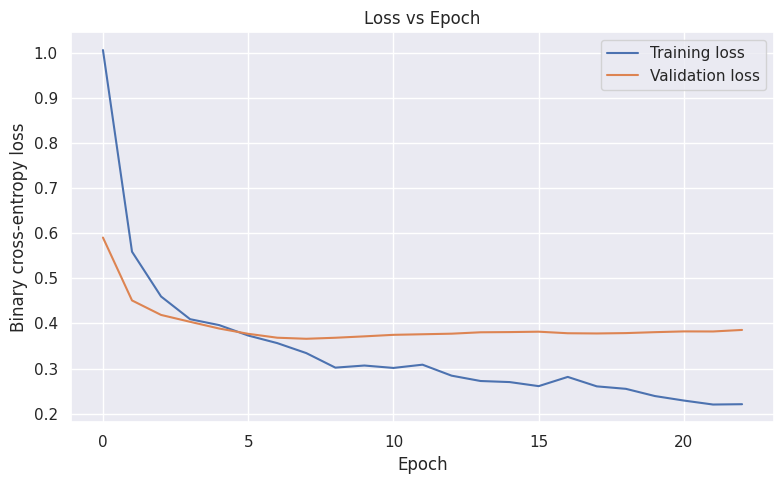

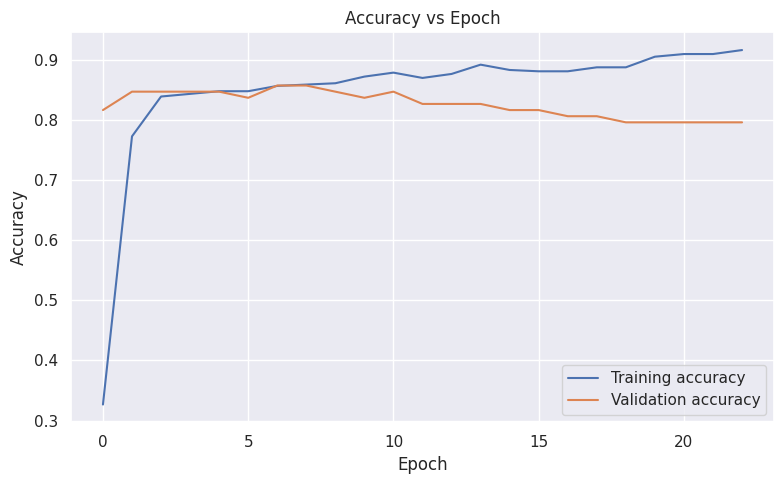

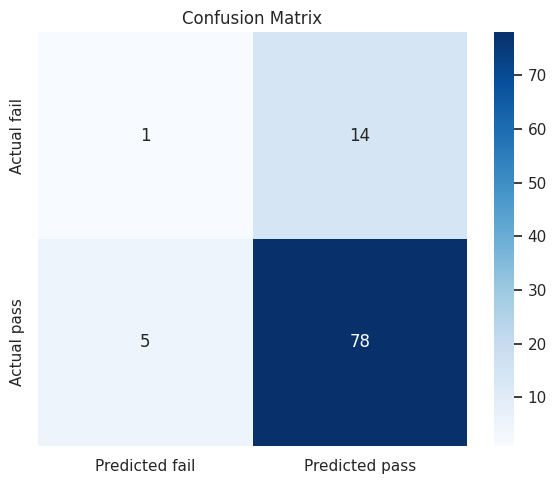

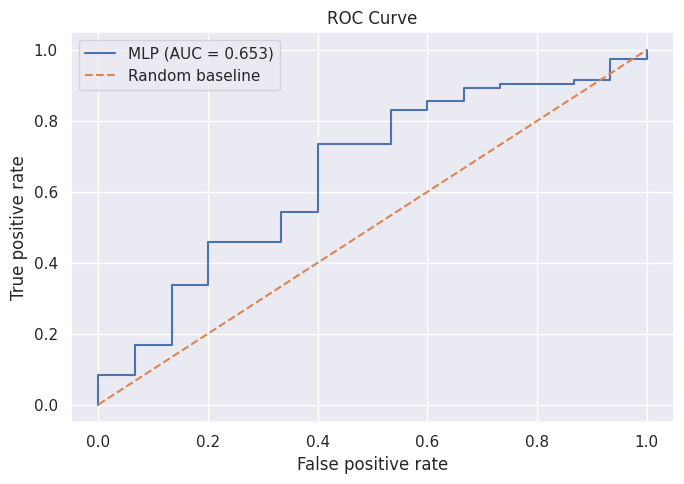

ROC AUC: 0.653


In [22]:
# 6. Evaluation on held-out test set
test_prob = model.predict(X_test_p, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print(classification_report(y_test, test_pred, target_names=["Fail", "Pass"], zero_division=0))

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy loss"); plt.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, test_pred, labels=[0,1])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted fail","Predicted pass"],
            yticklabels=["Actual fail","Actual pass"])
plt.title("Confusion Matrix")
plt.tight_layout(); plt.show()

fpr, tpr, thresholds = roc_curve(y_test, test_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"MLP (AUC = {roc_auc:.3f})")
plt.plot([0,1],[0,1], linestyle="--", label="Random baseline")
plt.title("ROC Curve")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.legend(); plt.tight_layout(); plt.show()
print("ROC AUC:", round(roc_auc, 4))


In [23]:
# 7. Basic hyperparameter experiment: compare hidden-layer widths.

,hidden_units,validation_loss,validation_accuracy
0,32,0.343838,0.846939
1,64,0.367592,0.836735
2,96,0.338530,0.836735


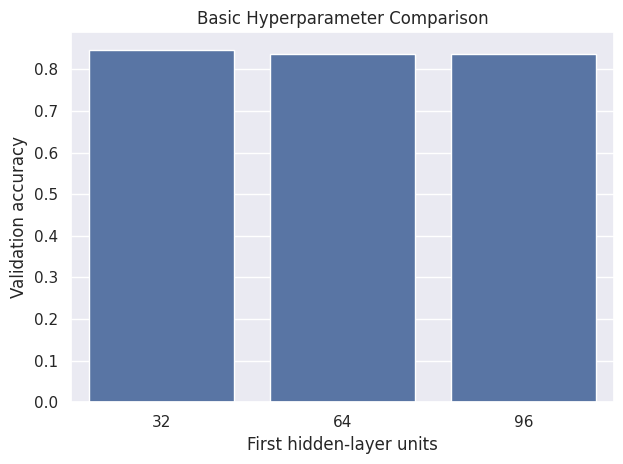

In [24]:
# Keep the same preprocessed split; this is a small exploratory comparison.
tuning_results = []
for width in [32, 64, 96]:
    trial = Sequential([
        Dense(width, activation="relu", input_shape=(X_train_p.shape[1],)),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    trial.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy", metrics=["accuracy"])
    trial.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
              epochs=80, batch_size=32,
              callbacks=[EarlyStopping(monitor="val_loss", patience=10,
                                       restore_best_weights=True)], verbose=0)
    val_loss, val_acc = trial.evaluate(X_val_p, y_val, verbose=0)
    tuning_results.append({"hidden_units": width, "validation_loss": val_loss,
                           "validation_accuracy": val_acc})
tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)
sns.barplot(data=tuning_df, x="hidden_units", y="validation_accuracy")
plt.title("Basic Hyperparameter Comparison")
plt.xlabel("First hidden-layer units"); plt.ylabel("Validation accuracy")
plt.tight_layout(); plt.show()


In [25]:
# 8. Export dataset used and model summary
df.to_csv("student_performance_cleaned.csv", index=False)
model.save("student_performance_mlp.keras")
print("Saved student_performance_cleaned.csv and student_performance_mlp.keras")


Saved student_performance_cleaned.csv and student_performance_mlp.keras
